In [1]:
import sys
import os
import math
from typing import NamedTuple

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold
from sklearn.metrics import r2_score

import jax
import jax.numpy as jnp
import optax


sys.path.append(os.path.join(os.getcwd(), 'import'))

from utils import read_utils
from utils import plot_utils
from utils import train_utils
from utils import artificializer

from models import bom
from models import hgm

In [39]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(bom)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/Work/Workspaces/UNIVIE/JetBrains/DataSpell/MSc_Thesis/worm-2025-fieseler/import/models/hgm.py'>

# Functions

In [40]:
class Lambdas(NamedTuple):
	loss_lambdas: tuple[float, float]
	reg_lambdas: tuple[float, float]
	cca_lambdas: tuple[float, float]

class PrepData(NamedTuple):
	N_mean: tuple[float, ...]
	N_std: tuple[float, ...]
	B_hl_mean: tuple[float, ...] | None = None
	B_hl_std: tuple[float, ...] | None = None

In [41]:
def assemble(filenames, traces, bom_models_scores, hgm_models_scores):
	neurons_labels = [traces[i].columns for i in range(len(filenames))]

	neuron_scores = dict()
	bom_models_avg_scores = [np.mean(scores, axis=0) for scores in bom_models_scores]
	hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, bom_models_avg_scores, hgm_models_avg_scores):
		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [42]:
def predict_wrapper(model, N, B_ll, params, neurons_labels):
	N_res_pred, N_res, N_rec = model.obtain(params,
											N, B_ll,
											PrepData(
												N_mean=tuple((map(float, N.mean(axis=0)))),
												N_std=tuple((map(float, jnp.where((N_std := jnp.std(N, axis=0)) == 0.0, 1.0, N_std)))),
											))
	return tuple(pd.DataFrame(data=traces, columns=neurons_labels) for traces in (N_res_pred, N_res, N_rec))

In [43]:
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

# 14
# selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
# 			   'RMDDR', 'SMDDR', 'SMDDL',					# C
# 			   'AVAR', 'AVAL',								# M
# 			   'ALA', 'AWBR', 'AWBR']						# O

# 24
# selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
# 			   'RMDDR', 'SMDDR', 'SMDDL',					# C
# 			   'AVAR', 'AVAL',								# M
# 			   'ALA', 'AWBR', 'AWBR',						# O
# 			   'SIAVL', 'RMED']			# good	, 'SMDVL', 'RMEV'

# 32
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
			   'RMDDR', 'SMDDR', 'SMDDL',					# C
			   'AVAR', 'AVAL',								# M
			   'ALA', 'AWBR', 'AWBR',						# O
			   ]
			   # 'DA01', 'RIVR', 'RIVL', 'URYDR']				# good	, 'URXR'

# selection_n_traces = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL', 'SMDDR', 'AVAR', 'ALA']
# selection_n_traces = ['VB02', 'DB01', 'DD01', 'SMDDR', 'AVAR', 'ALA']
# selection_n_traces = ['DB01']
selection_n_traces = ['VB02']

dims = 2  # just for the comparison cca


# read_ids = list(range(0, 33+1))
# read_ids = [0, 12, 14, 23, 29, 32]
# read_ids = [12, 14, 23, 29, 32]
read_ids = [14]
plot_id = read_ids[0]


gfp = False
if gfp:
	read_ids_gfp = list(range(0, 7+1))
	plot_id_gfp = 0

# read & preprocess (GCamp & GFP)

In [44]:
path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
file_ids_gcamp, filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, read_ids)

for i in range(len(filenames_gcamp)):
	mask = eigenworms_gcamp[i].notna().all(axis=1)
	#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
	discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
	eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
	traces_gcamp[i] = traces_gcamp[i][mask]

	#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
	#filenames_gcamp[i] = filenames_gcamp[i][mask]

discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


if gfp:
	path_gfp = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gfp')
	file_ids_gfp, filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp, read_ids_gfp)

	for i in range(len(filenames_gfp)):
		mask = eigenworms_gfp[i].notna().all(axis=1)
		#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
		discrete_states_gfp[i] = discrete_states_gfp[i][mask]
		eigenworms_gfp[i] = eigenworms_gfp[i][mask]
		traces_gfp[i] = traces_gfp[i][mask]

		#kymographs_gfp[i] = kymographs_gfp[i][mask]
		#filenames_gfp[i] = filenames_gfp[i][mask]

	discrete_states_gfp = [ds[selection_bhl] for ds in discrete_states_gfp]

# read results

In [45]:
w1 = 1E-3	# 1E-4
w2 = 1E-5	# 1E-4

hgm_load_name_gcamp = f'full/hgm_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'
bom_load_name_gcamp = f'full/bom_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'

if gfp:
	hgm_load_name_gfp = f'full/hgm_gfp_w1-{w1:.0E}_w2-{w2:.0E}'
	bom_load_name_gfp = f'full/bom_gfp_w1-{w1:.0E}_w2-{w2:.0E}'

In [46]:
hgm_losses_gcamp = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
hgm_models_losses_tr_gcamp = [losses[0] for losses in hgm_losses_gcamp]
hgm_models_losses_gcamp = [losses[1] for losses in hgm_losses_gcamp]
hgm_models_mpe_losses_tr_gcamp = [losses[2] for losses in hgm_losses_gcamp]
hgm_models_mpe_losses_gcamp = [losses[3] for losses in hgm_losses_gcamp]

bom_losses_gcamp = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
bom_models_losses_tr_gcamp = [losses[0] for losses in bom_losses_gcamp]
bom_models_losses_gcamp = [losses[1] for losses in bom_losses_gcamp]
bom_models_mpe_losses_tr_gcamp = [losses[2] for losses in bom_losses_gcamp]
bom_models_mpe_losses_gcamp = [losses[3] for losses in bom_losses_gcamp]

hgm_models_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)
bom_models_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

In [47]:
if gfp:
	hgm_losses_gfp = train_utils.load_losses(hgm_load_name_gfp)
	hgm_models_losses_tr_gfp = [losses[0] for losses in hgm_losses_gfp]
	hgm_models_losses_gfp = [losses[1] for losses in hgm_losses_gfp]
	hgm_models_mpe_losses_tr_gfp = [losses[2] for losses in hgm_losses_gfp]
	hgm_models_mpe_losses_gfp = [losses[3] for losses in hgm_losses_gfp]

	bom_losses_gfp = train_utils.load_losses(bom_load_name_gfp)
	bom_models_losses_tr_gfp = [losses[0] for losses in bom_losses_gfp]
	bom_models_losses_gfp = [losses[1] for losses in bom_losses_gfp]
	bom_models_mpe_losses_tr_gfp = [losses[2] for losses in bom_losses_gfp]
	bom_models_mpe_losses_gfp = [losses[3] for losses in bom_losses_gfp]

	hgm_models_params_gfp = train_utils.load_params(hgm_load_name_gfp)
	bom_models_params_gfp = train_utils.load_params(bom_load_name_gfp)

# GCAMP

In [48]:
# plot_utils.plot_traces(f'[{filenames_gcamp[file_ids_gcamp.index(plot_id)]}] gcamp neural traces',
# 					   discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
# 					   traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n],
# 					   plots_per_row=1, ylimits=None)

## predict & score

In [49]:
bom_pres_res_rec_gcamp = [[
	predict_wrapper(bom, traces_gcamp[i].values, eigenworms_gcamp[i].values, params, traces_gcamp[i].columns) for params in bom_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

hgm_pres_res_rec_gcamp = [[
	predict_wrapper(hgm, traces_gcamp[i].values, eigenworms_gcamp[i].values, params, traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]
] for i in range(len(traces_gcamp))]

In [50]:
# splits_gcamp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i]['REV'].values)) for i in range(len(filenames_gcamp))]
#
# bom_models_scores_gcamp = [
# 	np.array([
# 		[(r2_score(t, t_p) if t.var() > 0 else 0) for t, t_p in zip(trace.values[eval].T, trace_pred.values[eval].T)]
# 		for (trace_pred, trace, _), (_, eval) in zip(pres_res_rec, splits)])
# 	for pres_res_rec, splits in zip(bom_pres_res_rec_gcamp, splits_gcamp)
# ]
# hgm_models_scores_gcamp = [
# 	np.array([
# 		[(r2_score(t, t_p) if t.var() > 0 else 0) for t, t_p in zip(trace.values[eval].T, trace_pred.values[eval].T)]
# 		for (trace_pred, trace, _), (_, eval) in zip(pres_res_rec, splits)])
# 	for pres_res_rec, splits in zip(hgm_pres_res_rec_gcamp, splits_gcamp)
# ]



bom_models_scores_gcamp = list()
hgm_models_scores_gcamp = list()

for i in range(len(filenames_gcamp)):
	splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i]['REV'].values))

	N = traces_gcamp[i].values
	B_ll = eigenworms_gcamp[i].values
	B_hl = discrete_states_gcamp[i].values

	bom_neuron_scores_per_split = list()
	hgm_neuron_scores_per_split = list()

	for s_id, (train, eval) in enumerate(splits):
		N_train, N_eval = N[train], N[eval]
		B_hl_train, B_hl_eval = B_hl[train], B_hl[eval]
		B_ll_train, B_ll_eval = B_ll[train], B_ll[eval]

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_eval = PrepData(
			N_mean=tuple((map(float, N_eval.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		bom_params = bom_models_params_gcamp[i][s_id]
		bom_score_per_neuron = bom.score_fn(bom_params, N_eval, B_ll_eval, prep_data_eval)
		bom_neuron_scores_per_split.append(bom_score_per_neuron)

		hgm_params = hgm_models_params_gcamp[i][s_id]
		hgm_score_per_neuron = hgm.score_fn(hgm_params, N_eval, B_ll_eval, prep_data_eval)
		hgm_neuron_scores_per_split.append(hgm_score_per_neuron)

	bom_models_scores_gcamp.append(np.array(bom_neuron_scores_per_split))
	hgm_models_scores_gcamp.append(np.array(hgm_neuron_scores_per_split))

## losses

In [51]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: train',
# 							  filenames_gcamp,
# 							  hgm_models_losses_tr_gcamp, bom_models_losses_tr_gcamp,
# 							  plots_per_row=4, ylimits=None)

In [52]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: test',
# 							  filenames_gcamp,
# 							  hgm_models_losses_gcamp, bom_models_losses_gcamp,
# 							  plots_per_row=4, ylimits=None)

In [53]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe train',
# 							  filenames_gcamp,
# 							  hgm_models_mpe_losses_tr_gcamp, bom_models_mpe_losses_tr_gcamp,
# 							  plots_per_row=4, ylimits=(0.03, 0.06))

In [54]:
# plot_utils.plot_losses_splits('gcamp hgm vs bom: mpe test',
# 							  filenames_gcamp,
# 							  hgm_models_mpe_losses_gcamp, bom_models_mpe_losses_gcamp,
# 							  plots_per_row=4, ylimits=None)

In [ ]:
def stuff(read_ids, plot_id):
	selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

	# 14
	# selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
	# 			   'SMDDR', 'SMDDL',					# C		'RMDDR',
	# 			   'AVAR', 'AVAL',								# M
	# 			   'ALA', 'AWBR', 'AWBR']						# O

	# 24
	# selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',		# paper
	# 			   'SMDDR', 'SMDDL',					# C		'RMDDR',
	# 			   'AVAR', 'AVAL',								# M
	# 			   'ALA', 'AWBR', 'AWBR',						# O
	# 			   'SIAVL', 'RMED']			# good	, 'SMDVL', 'RMEV'

	# 32
	selection_n = ['VB02', 'DB01', 'DD01', 'AVBL',		# paper
				   'SMDDR', 'SMDDL',					# C		'RMDDR',
				   'AVAR', 'AVAL',								# M
				   'ALA', 'AWBR', 'AWBR',						# O
				   ]



	w1 = 1E-3	# 1E-4
	w2 = 1E-5	# 1E-4

	hgm_load_name_gcamp = f'full/hgm_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'
	bom_load_name_gcamp = f'full/bom_gcamp_w1-{w1:.0E}_w2-{w2:.0E}'






	path = os.path.join(read_utils.get_data_path(), 'worm-2025-fieseler', 'exported_data_gcamp')
	file_ids_gcamp, filenames_gcamp, continuous_behaviors_gcamp, discrete_states_gcamp, eigenworms_gcamp, kymographs_gcamp, traces_gcamp = read_utils.get_data(path, read_ids)

	for i in range(len(filenames_gcamp)):
		mask = eigenworms_gcamp[i].notna().all(axis=1)
		#continuous_behaviors_gcamp[i] = continuous_behaviors_gcamp[i][mask]
		discrete_states_gcamp[i] = discrete_states_gcamp[i][mask]
		eigenworms_gcamp[i] = eigenworms_gcamp[i][mask]
		traces_gcamp[i] = traces_gcamp[i][mask]

		#kymographs_gcamp[i] = kymographs_gcamp[i][mask]
		#filenames_gcamp[i] = filenames_gcamp[i][mask]

	discrete_states_gcamp = [ds[selection_bhl] for ds in discrete_states_gcamp]


	hgm_losses_gcamp = train_utils.load_losses(hgm_load_name_gcamp, filenames_gcamp)
	hgm_models_losses_tr_gcamp = [losses[0] for losses in hgm_losses_gcamp]
	hgm_models_losses_gcamp = [losses[1] for losses in hgm_losses_gcamp]
	hgm_models_mpe_losses_tr_gcamp = [losses[2] for losses in hgm_losses_gcamp]
	hgm_models_mpe_losses_gcamp = [losses[3] for losses in hgm_losses_gcamp]

	bom_losses_gcamp = train_utils.load_losses(bom_load_name_gcamp, filenames_gcamp)
	bom_models_losses_tr_gcamp = [losses[0] for losses in bom_losses_gcamp]
	bom_models_losses_gcamp = [losses[1] for losses in bom_losses_gcamp]
	bom_models_mpe_losses_tr_gcamp = [losses[2] for losses in bom_losses_gcamp]
	bom_models_mpe_losses_gcamp = [losses[3] for losses in bom_losses_gcamp]

	hgm_models_params_gcamp = train_utils.load_params(hgm_load_name_gcamp, filenames_gcamp)
	bom_models_params_gcamp = train_utils.load_params(bom_load_name_gcamp, filenames_gcamp)

	bom_pres_res_rec_gcamp = [[
		predict_wrapper(bom, traces_gcamp[i].values, eigenworms_gcamp[i].values, params, traces_gcamp[i].columns) for params in bom_models_params_gcamp[i]
	] for i in range(len(traces_gcamp))]

	hgm_pres_res_rec_gcamp = [[
		predict_wrapper(hgm, traces_gcamp[i].values, eigenworms_gcamp[i].values, params, traces_gcamp[i].columns) for params in hgm_models_params_gcamp[i]
	] for i in range(len(traces_gcamp))]








	bom_models_scores_gcamp = list()
	hgm_models_scores_gcamp = list()

	for i in range(len(filenames_gcamp)):
		splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gcamp[i].shape[0]), discrete_states_gcamp[i]['REV'].values))

		N = traces_gcamp[i].values
		B_ll = eigenworms_gcamp[i].values
		B_hl = discrete_states_gcamp[i].values

		bom_neuron_scores_per_split = list()
		hgm_neuron_scores_per_split = list()

		for s_id, (train, eval) in enumerate(splits):
			N_train, N_eval = N[train], N[eval]
			B_hl_train, B_hl_eval = B_hl[train], B_hl[eval]
			B_ll_train, B_ll_eval = B_ll[train], B_ll[eval]

			prep_data_train = PrepData(
				N_mean=tuple((map(float, N_train.mean(axis=0)))),
				N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
				B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
				B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
			)
			prep_data_eval = PrepData(
				N_mean=tuple((map(float, N_eval.mean(axis=0)))),
				N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
				B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
				B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
			)

			bom_params = bom_models_params_gcamp[i][s_id]
			bom_score_per_neuron = bom.score_fn(bom_params, N_eval, B_ll_eval, prep_data_eval)
			bom_neuron_scores_per_split.append(bom_score_per_neuron)

			hgm_params = hgm_models_params_gcamp[i][s_id]
			hgm_score_per_neuron = hgm.score_fn(hgm_params, N_eval, B_ll_eval, prep_data_eval)
			hgm_neuron_scores_per_split.append(hgm_score_per_neuron)

		bom_models_scores_gcamp.append(np.array(bom_neuron_scores_per_split))
		hgm_models_scores_gcamp.append(np.array(hgm_neuron_scores_per_split))















	neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, bom_models_scores_gcamp, hgm_models_scores_gcamp)
	selection_n = [n for n in selection_n if n in neuron_scores_gcamp.keys()]

	# best hgm scores
	neuron_hgmss = {key: np.mean(neuron_scores_gcamp[key][1]) for key in neuron_scores_gcamp.keys()}
	selection_n_perf = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:int(len(neuron_scores_gcamp) / 100 * 25)]

	# best hgm-bom improvements
	neuron_diffs = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp.keys()}
	selection_n_impr = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:int(len(neuron_scores_gcamp) / 100 * 25)]

	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
									 limits=(-0.6, 0.6, -0.6, 0.6), plot_size=30,
									 save_name=f'{plot_id}-perf-single-{filenames_gcamp[file_ids_gcamp.index(plot_id)]}')

	# plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_perf}, None,
	# 								 limits=(-0.5, 0.5, -0.5, 0.5), plot_size=30)

	plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
									 limits=(-0.6, 0.6, -0.6, 0.6), plot_size=30,
									 save_name=f'{plot_id}-perf-all-{filenames_gcamp[file_ids_gcamp.index(plot_id)]}')

In [ ]:
importlib.reload(plot_utils)
for _id in [19, 32]:
	stuff([_id], _id)

## performance

In [55]:
neuron_scores_gcamp = assemble(filenames_gcamp, traces_gcamp, bom_models_scores_gcamp, hgm_models_scores_gcamp)
selection_n = [n for n in selection_n if n in neuron_scores_gcamp.keys()]
selection_n_traces = [n for n in selection_n_traces if n in traces_gcamp[file_ids_gcamp.index(plot_id)].keys()]

In [56]:
# best hgm scores
neuron_hgmss = {key: np.mean(neuron_scores_gcamp[key][1]) for key in neuron_scores_gcamp.keys()}
selection_n_perf = [label for label in list(reversed(list(np.array(list(neuron_hgmss.keys()))[np.argsort(np.array(list(neuron_hgmss.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:int(len(neuron_scores_gcamp) / 100 * 25)]

# best hgm-bom improvements
neuron_diffs = {key: np.mean(neuron_scores_gcamp[key][1] - neuron_scores_gcamp[key][0]) for key in neuron_scores_gcamp.keys()}
selection_n_impr = [label for label in list(reversed(list(np.array(list(neuron_diffs.keys()))[np.argsort(np.array(list(neuron_diffs.values())))]))) if label in traces_gcamp[file_ids_gcamp.index(plot_id)].columns][:int(len(neuron_scores_gcamp) / 100 * 25)]

In [ ]:
plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=(-0.5, 0.5, -0.5, 0.5), plot_size=30,
								 save_name=f'{plot_id}-perf-single-{filenames_gcamp[file_ids_gcamp.index(plot_id)]}')

# plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_perf}, None,
# 								 limits=(-0.5, 0.5, -0.5, 0.5), plot_size=30)
#
plot_utils.plot_performance_plot(neuron_scores_gcamp, None,
								 limits=(-0.5, 0.5, -0.5, 0.5), plot_size=30,
								 save_name=f'{plot_id}-perf-all-{filenames_gcamp[file_ids_gcamp.index(plot_id)]}')

In [ ]:
# raise Exception

In [ ]:
plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n}, None,
								 limits=(-1, 0.5, -0.15, 0.25), plot_size=30,
								 save_name=f'{plot_id}-improvement-selected')

plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n_impr}, None,
								 limits=(-1, 0.5, -0.15, 0.25), plot_size=30,
								 save_name=f'{plot_id}-improvement-best')

plot_utils.plot_improvement_plot(neuron_scores_gcamp, None,
								 limits=(-1, 0.5, -0.15, 0.25), plot_size=30,
								 save_name=f'{plot_id}-improvement-all')

## traces check

In [ ]:
_, _, cca_rec_gcamp, _, _, _, _, _ = train_utils.get_manifolds(traces_gcamp, discrete_states_gcamp, n_cc=dims, n_pc=0)
cca_res_gcamp = [pd.DataFrame(data=trace_gcamp.values - cca_rec_gcamp_.values, columns=trace_gcamp.columns) for trace_gcamp, cca_rec_gcamp_ in zip(traces_gcamp, cca_rec_gcamp)]

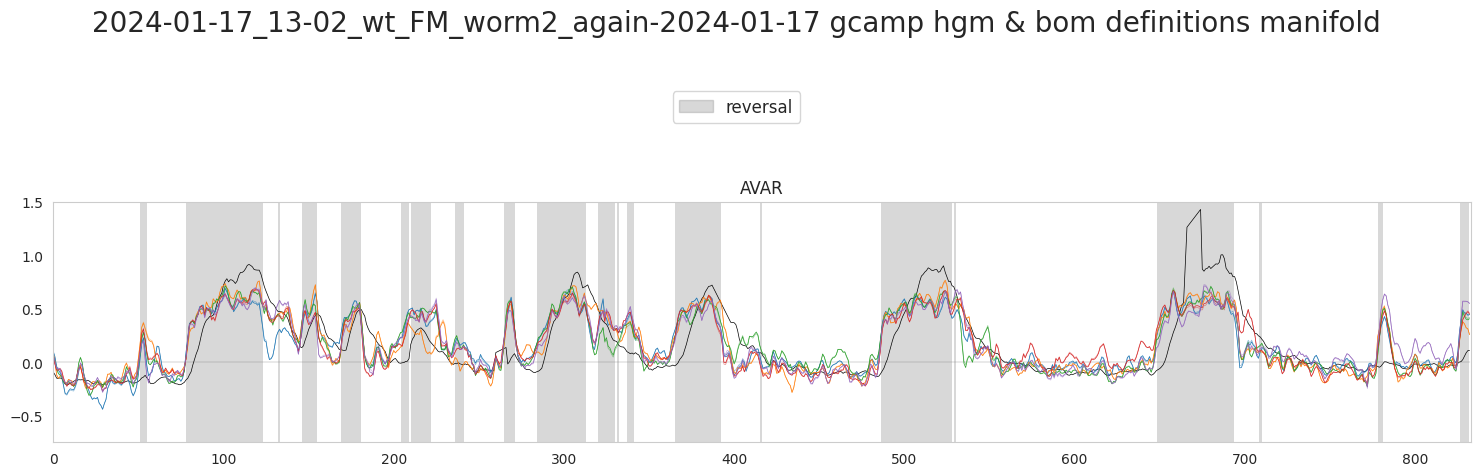

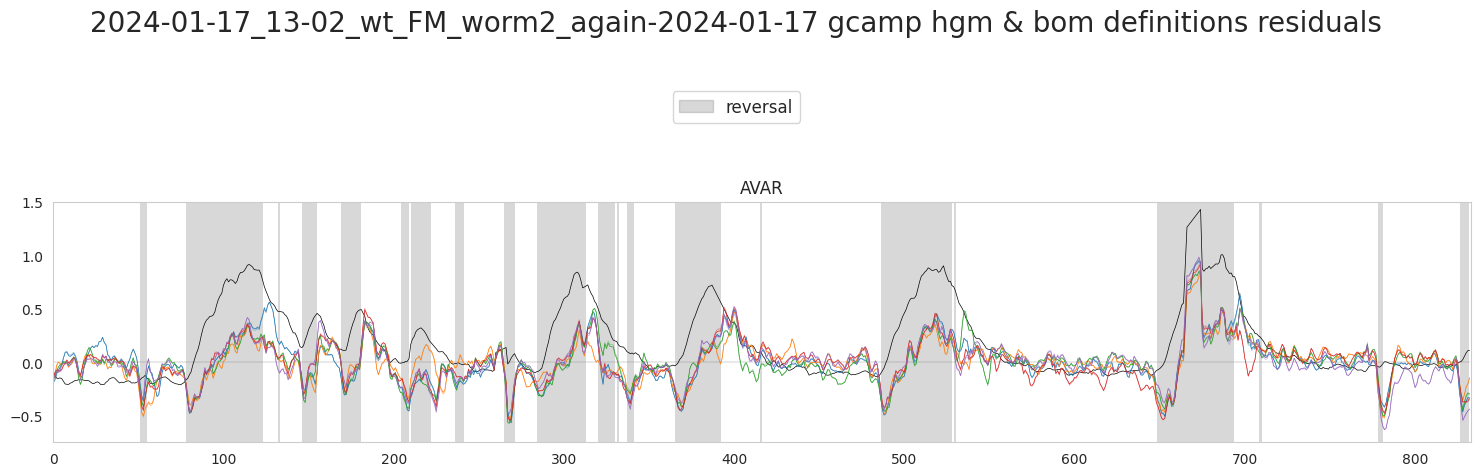

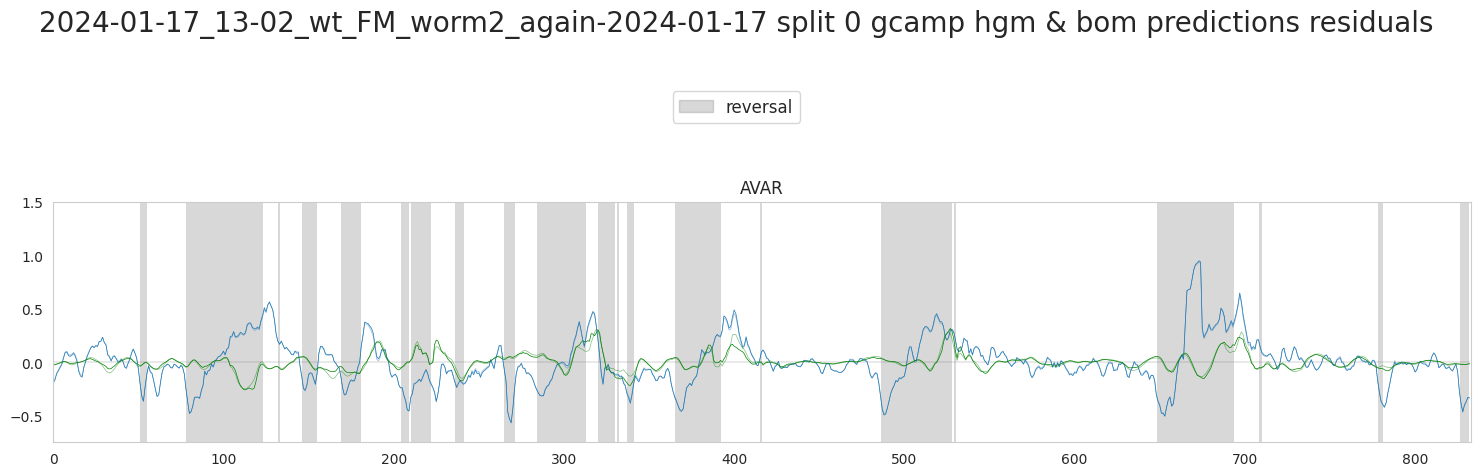

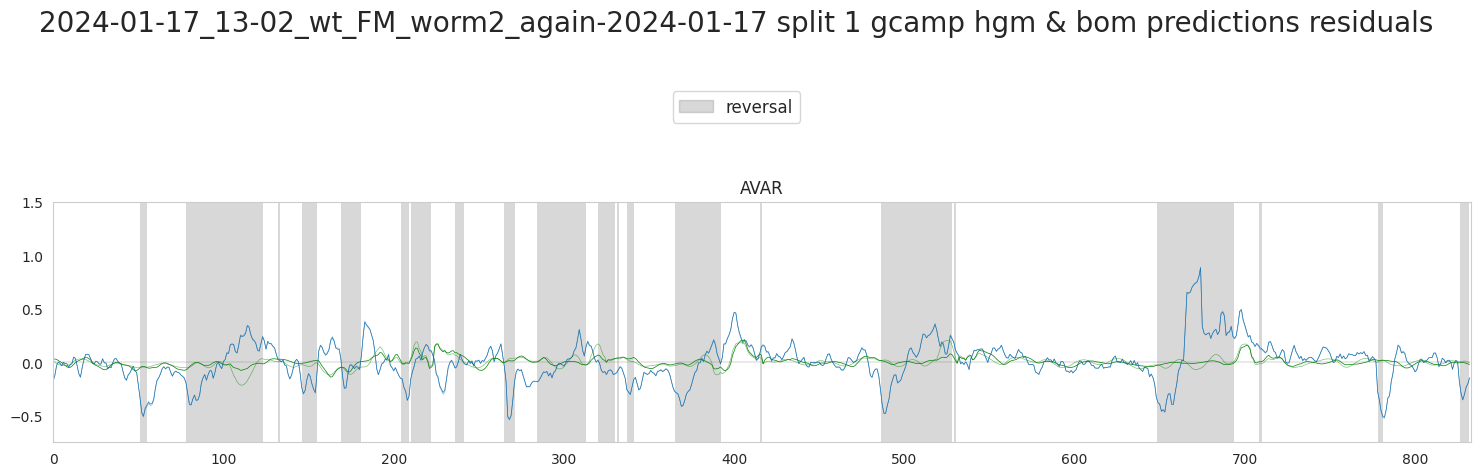

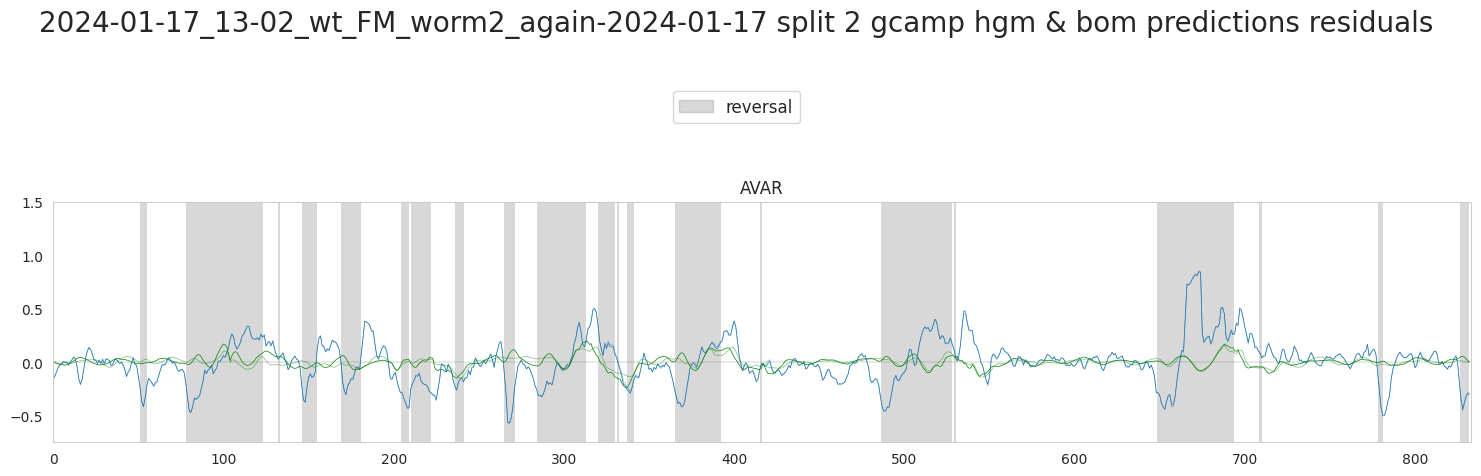

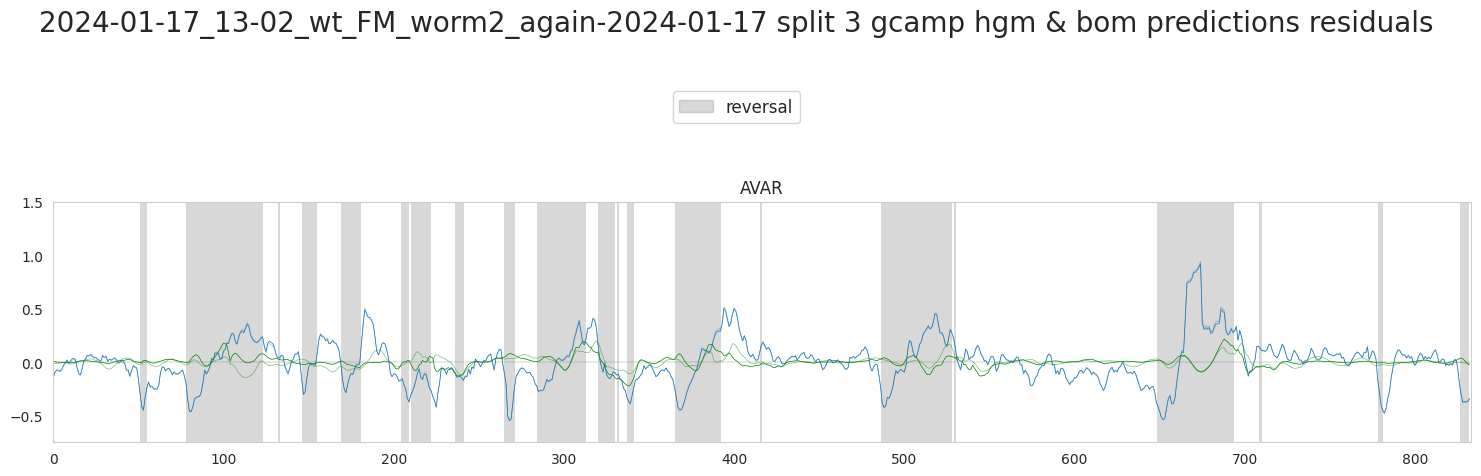

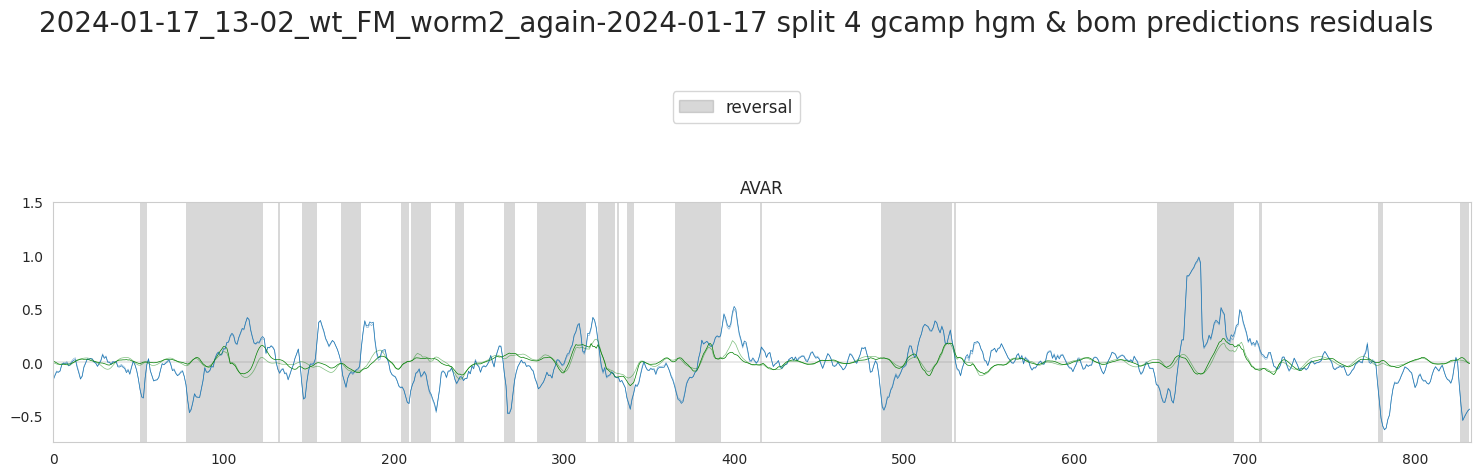

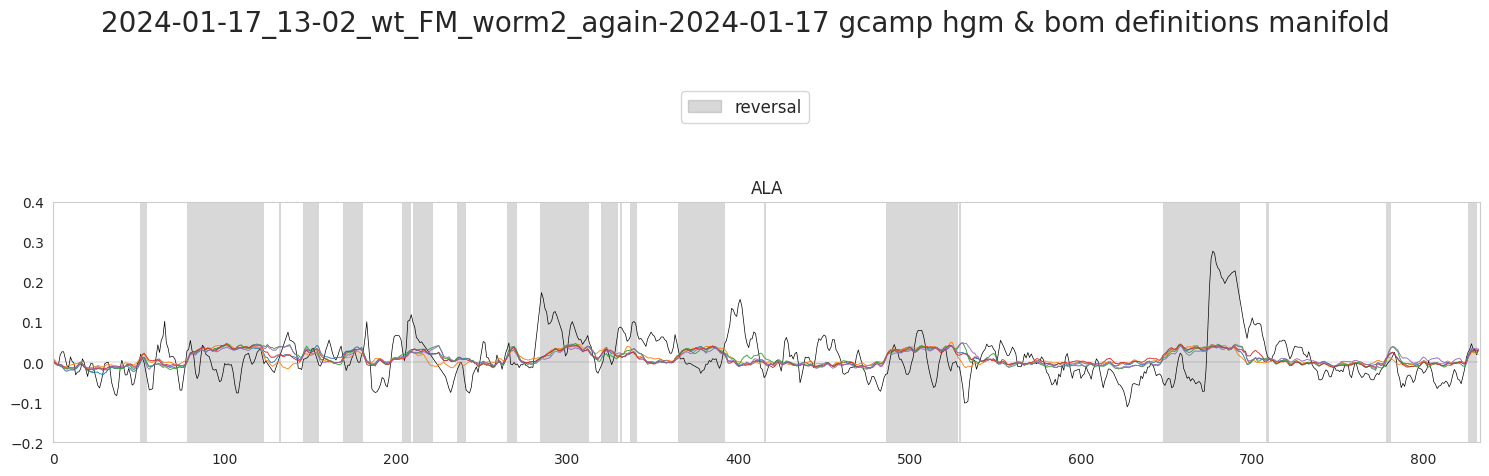

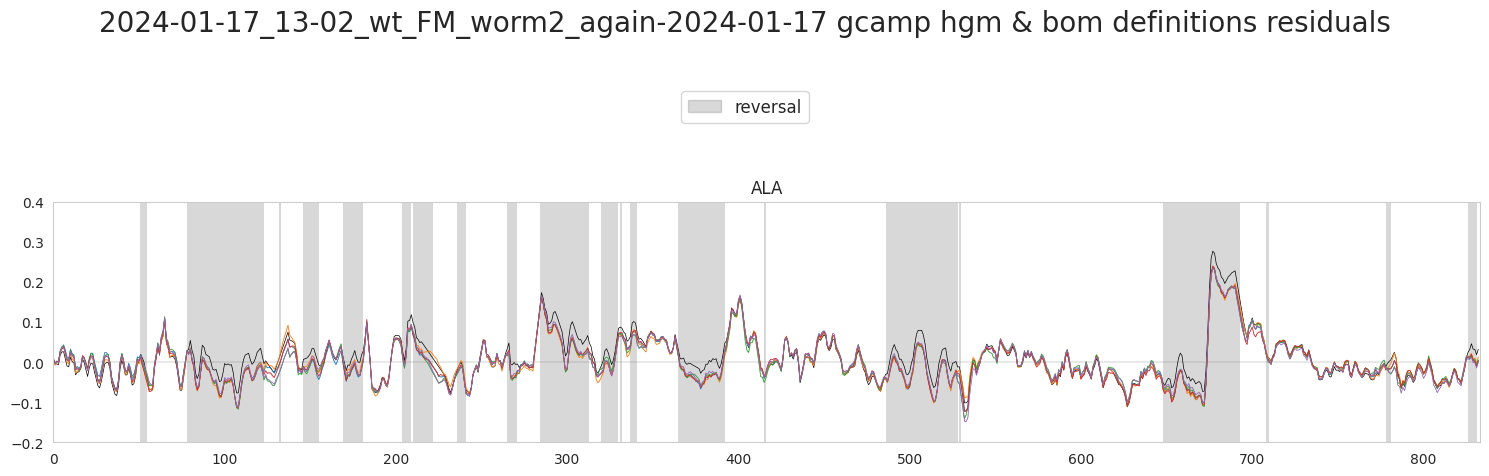

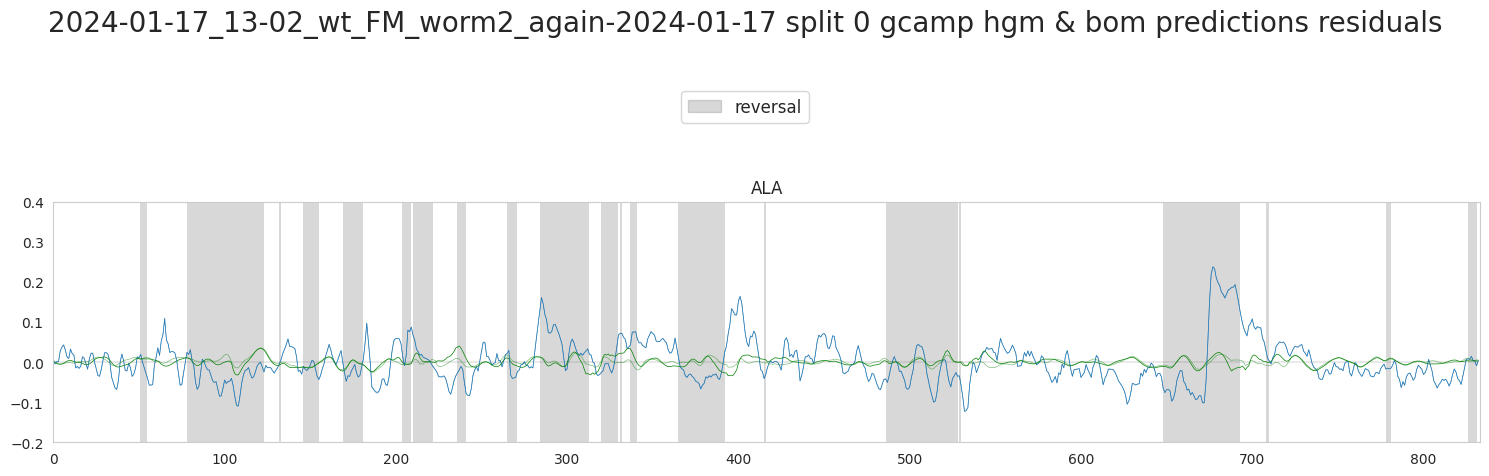

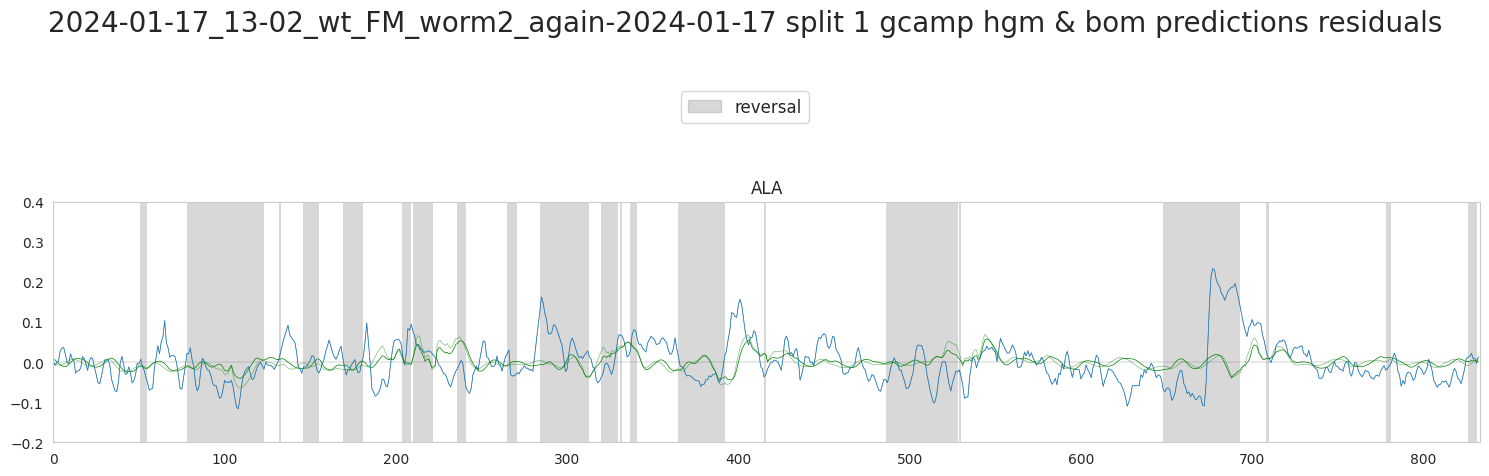

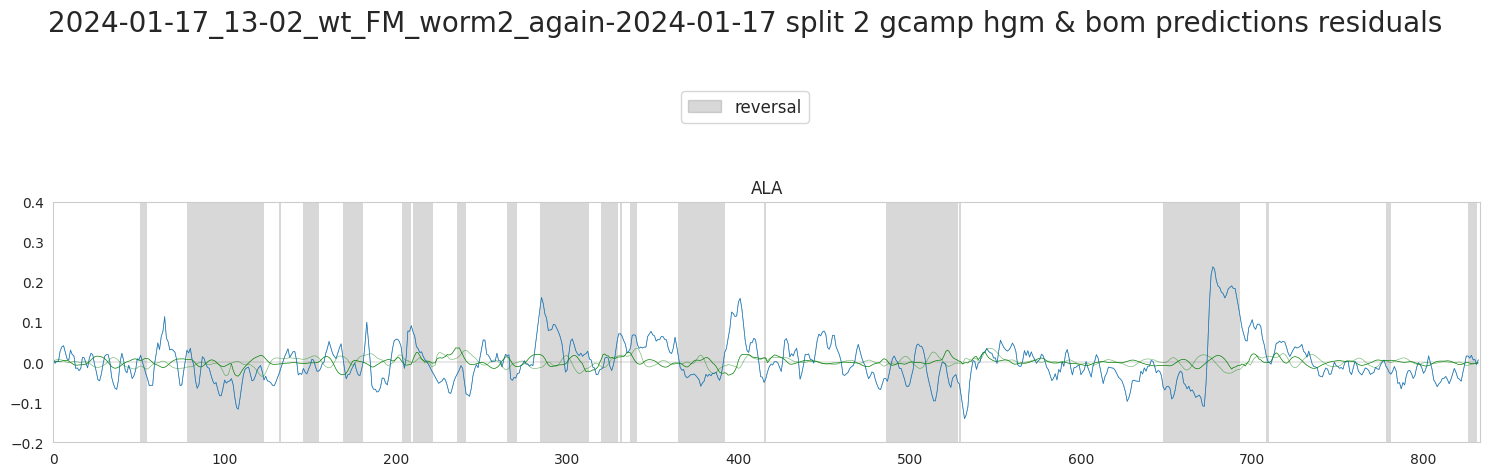

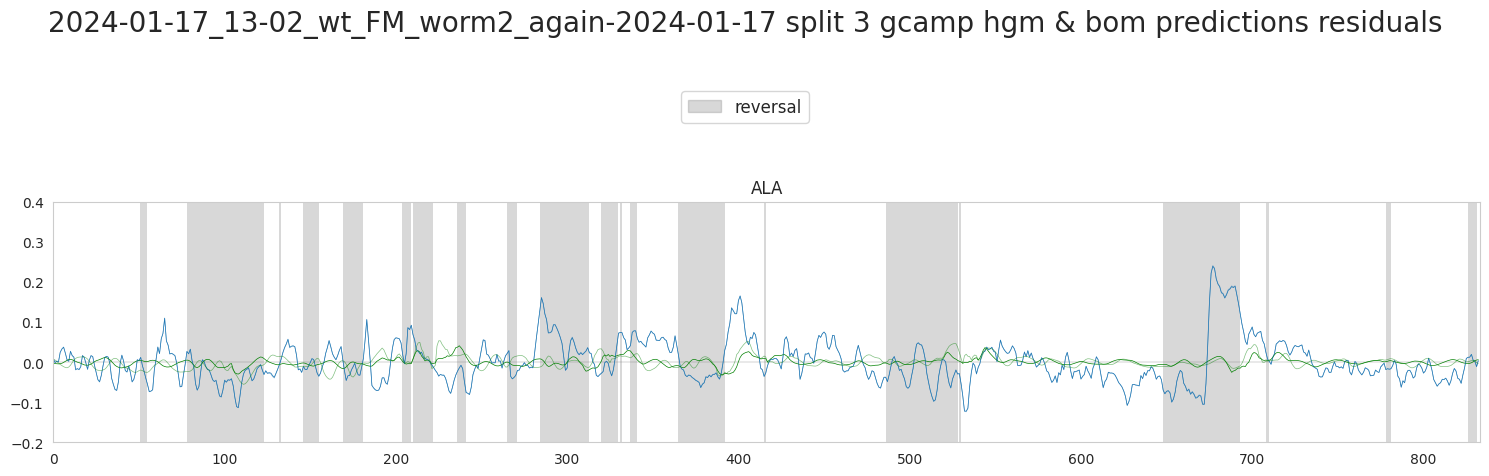

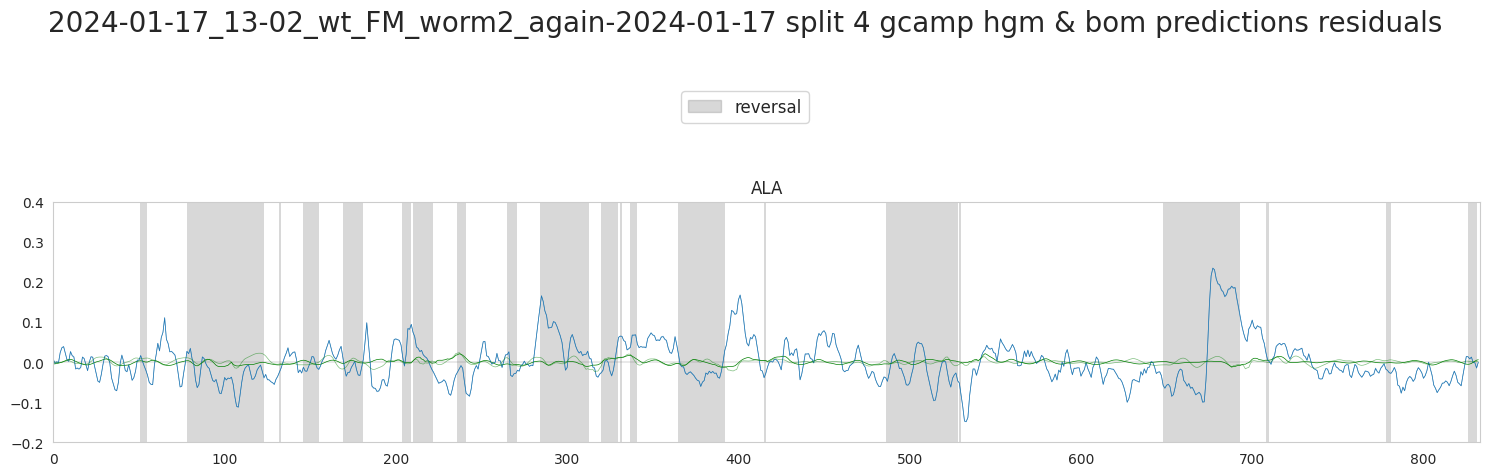

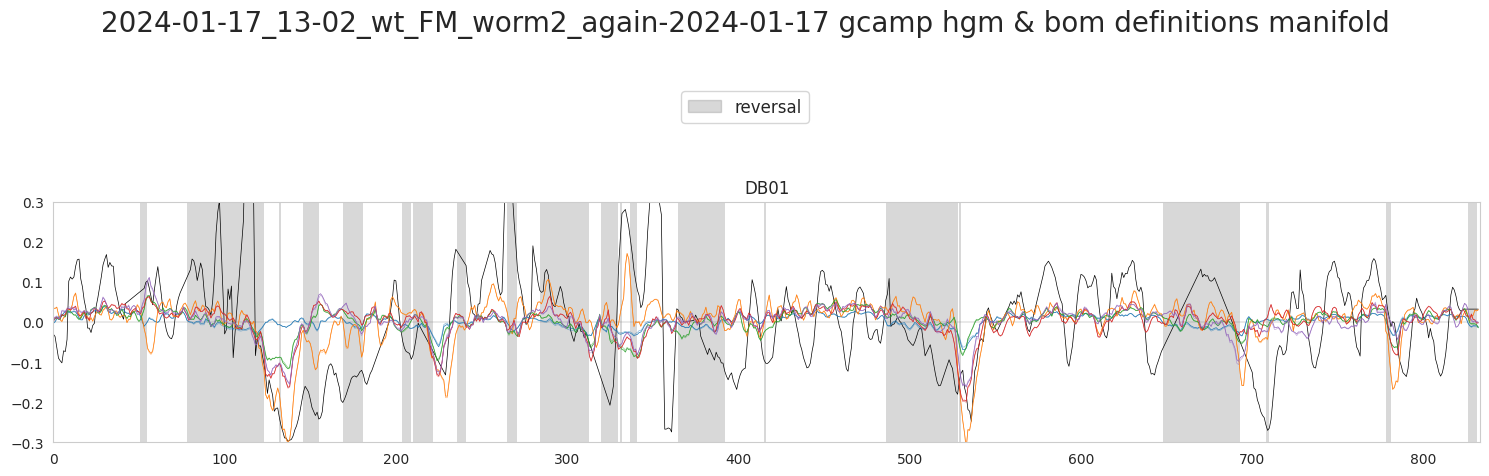

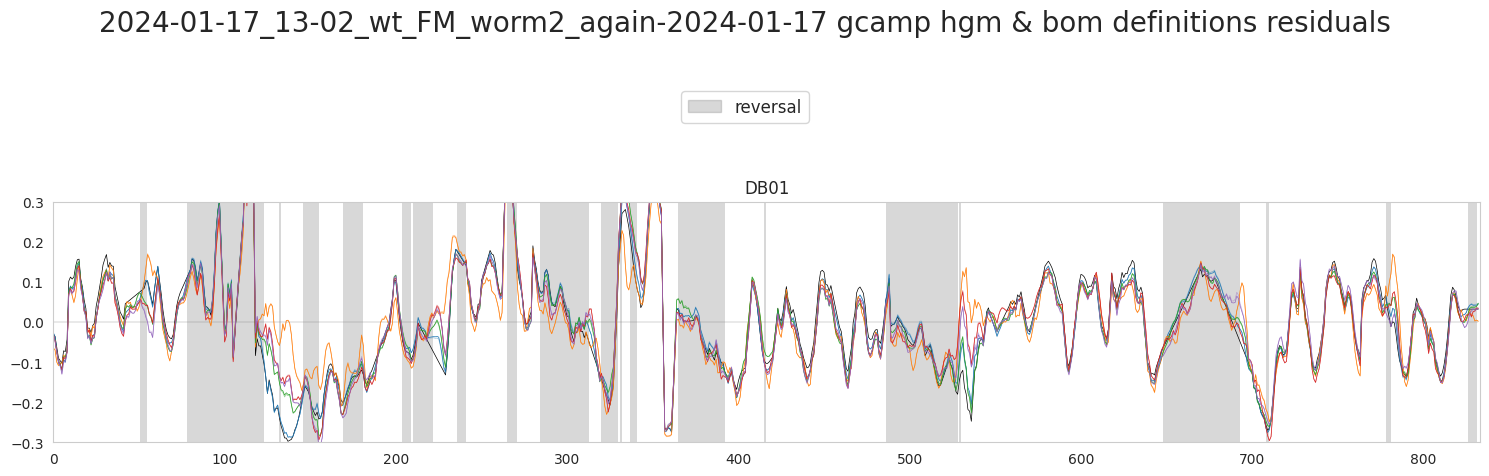

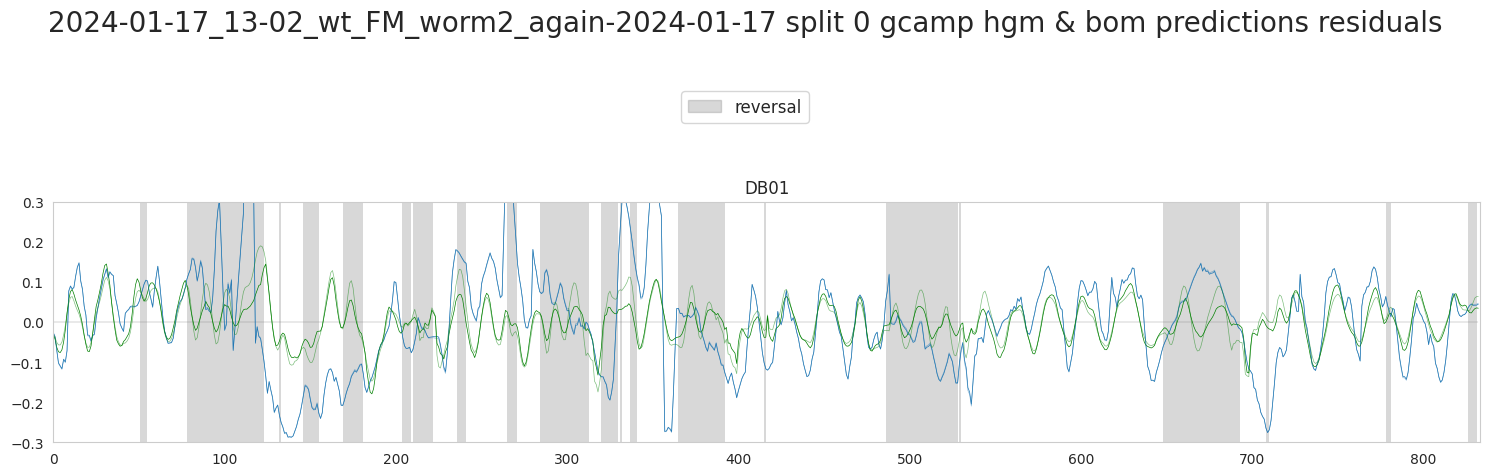

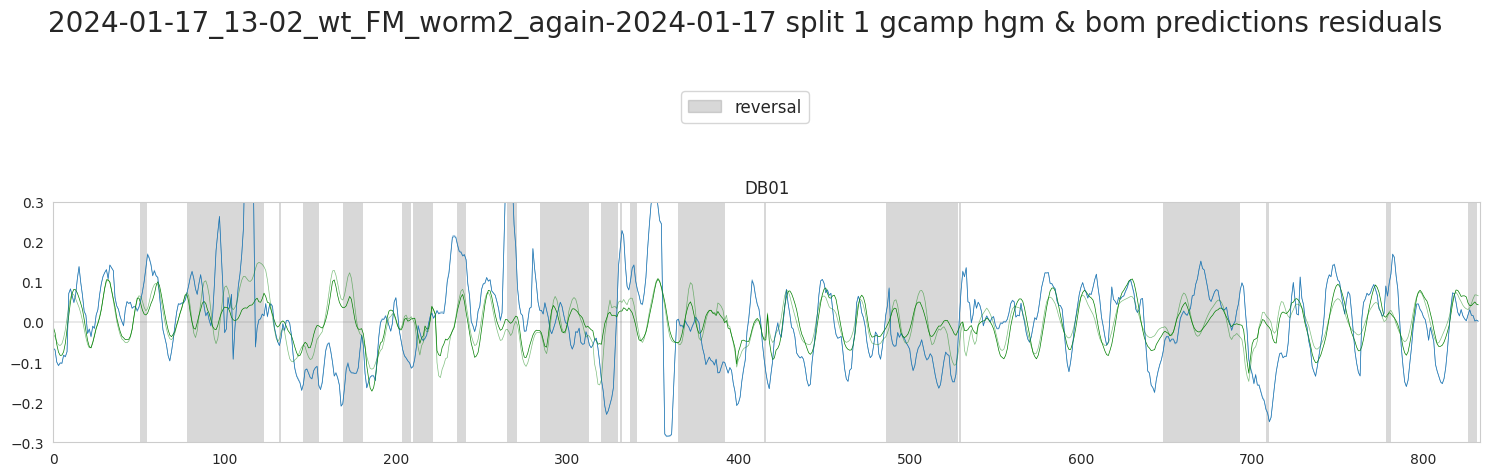

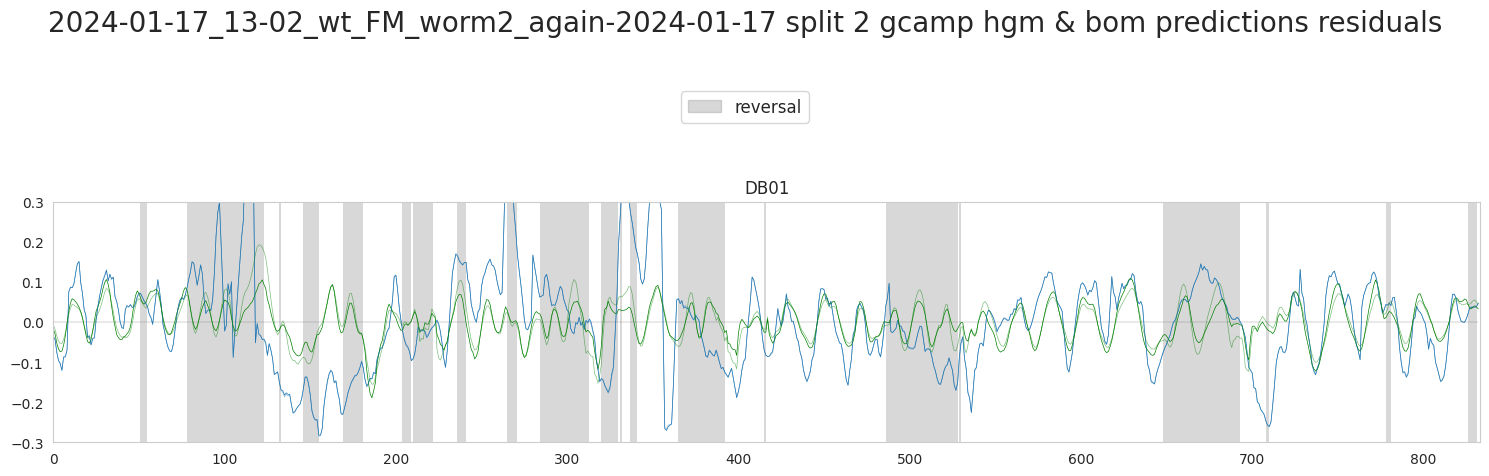

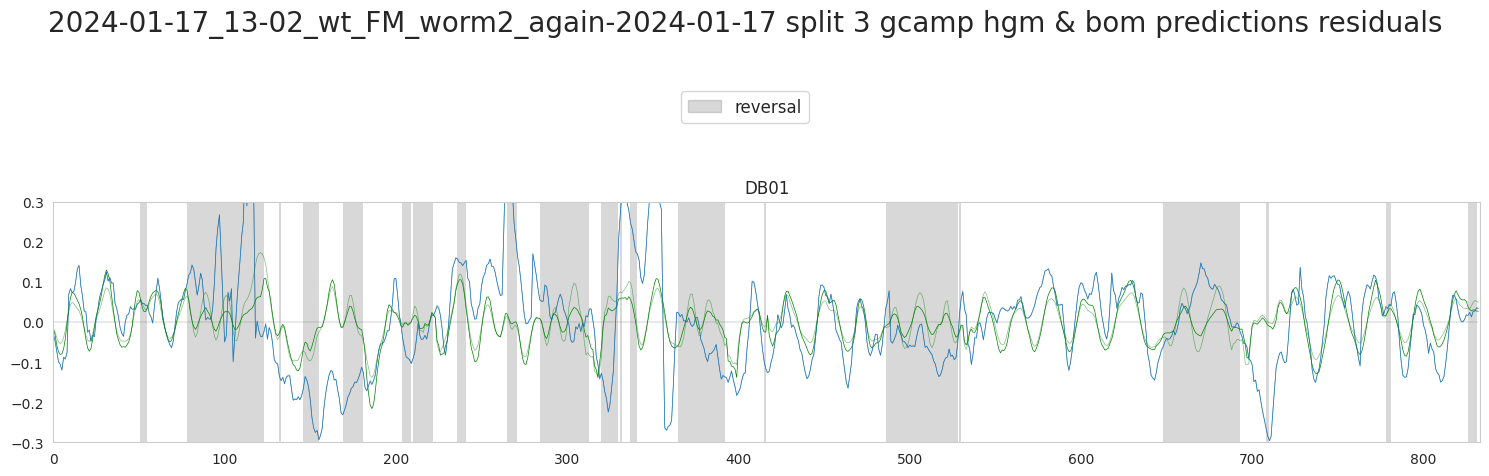

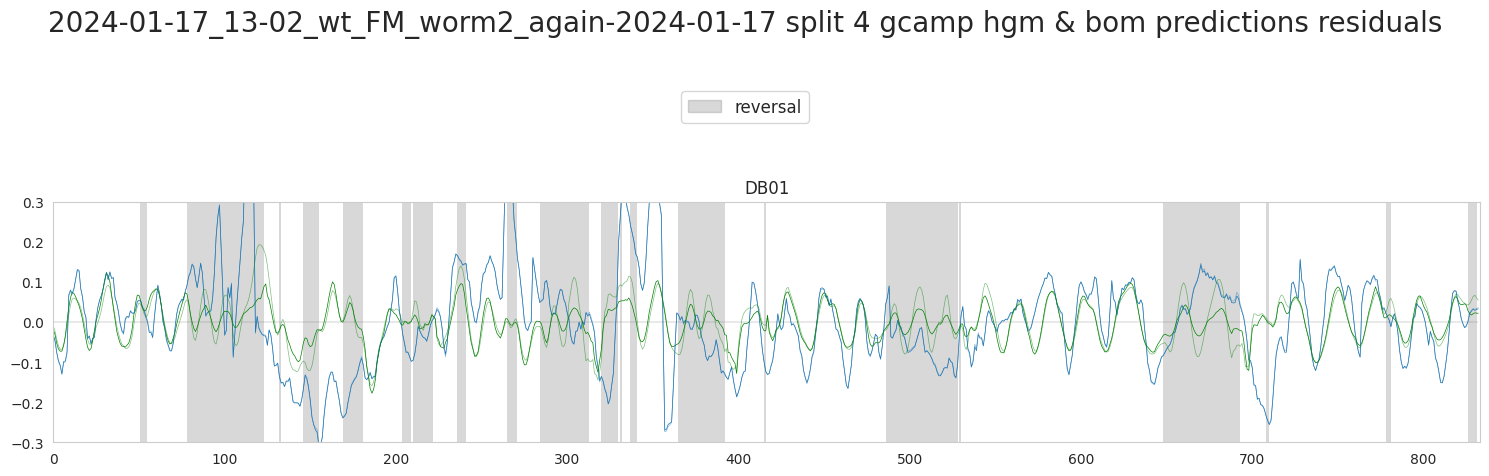

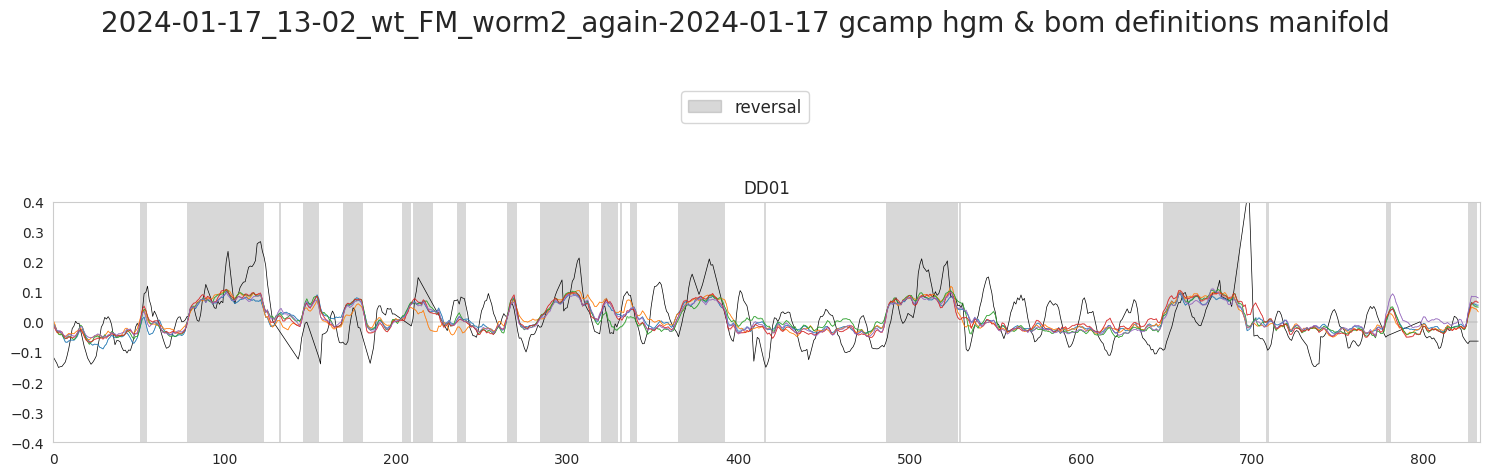

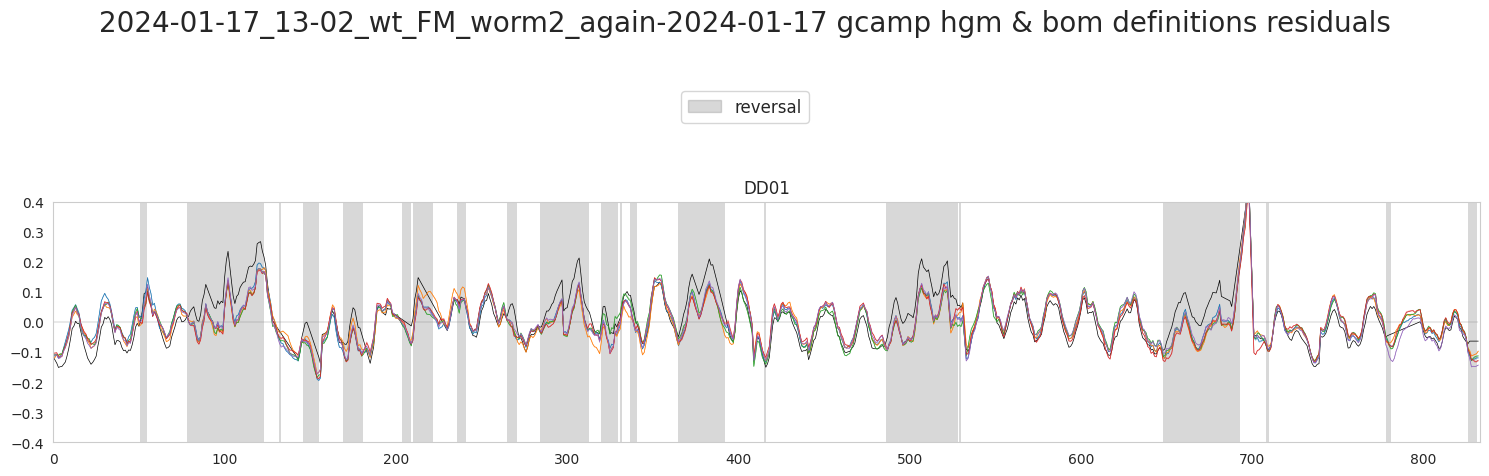

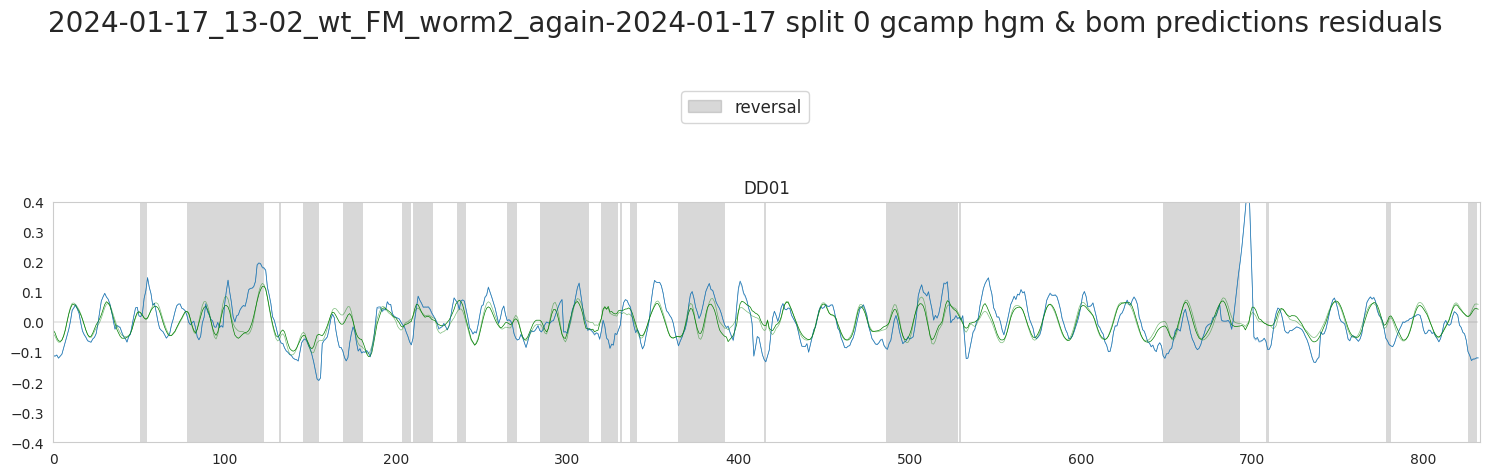

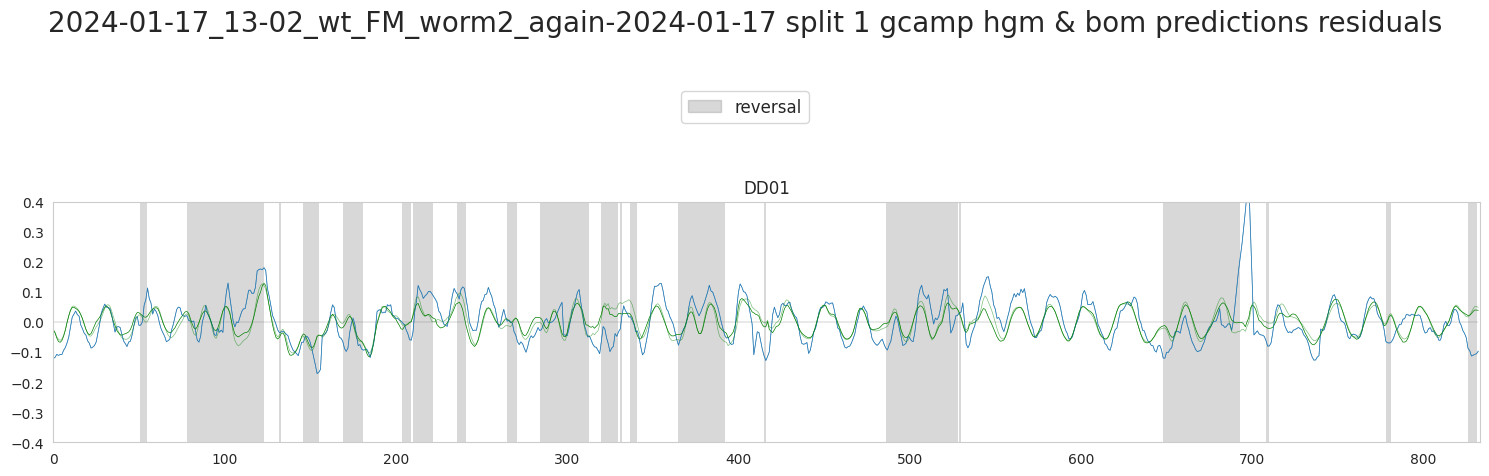

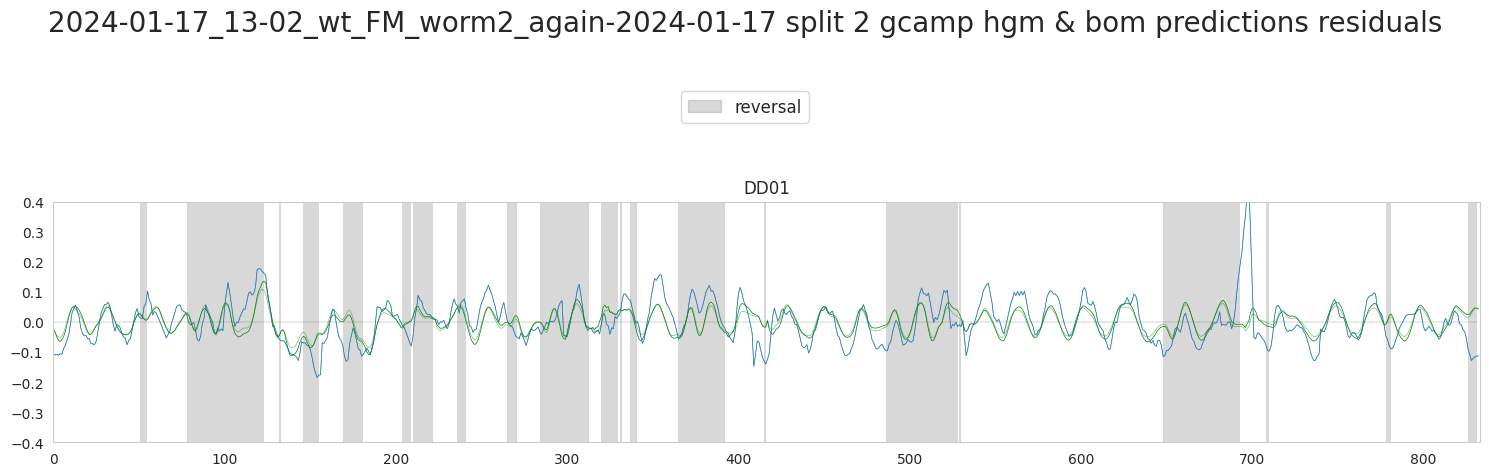

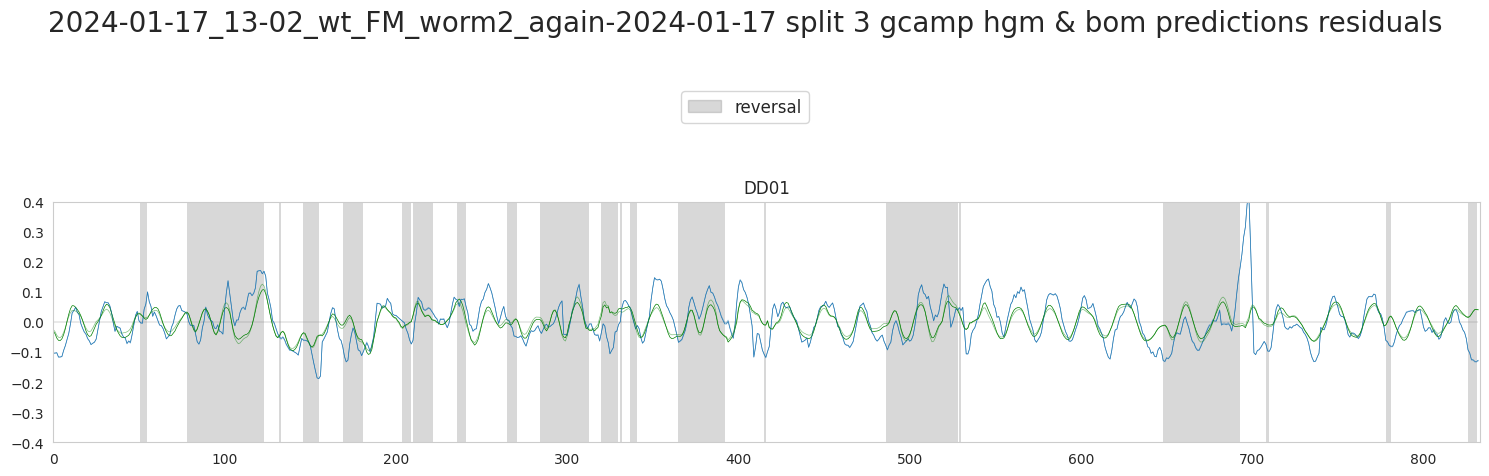

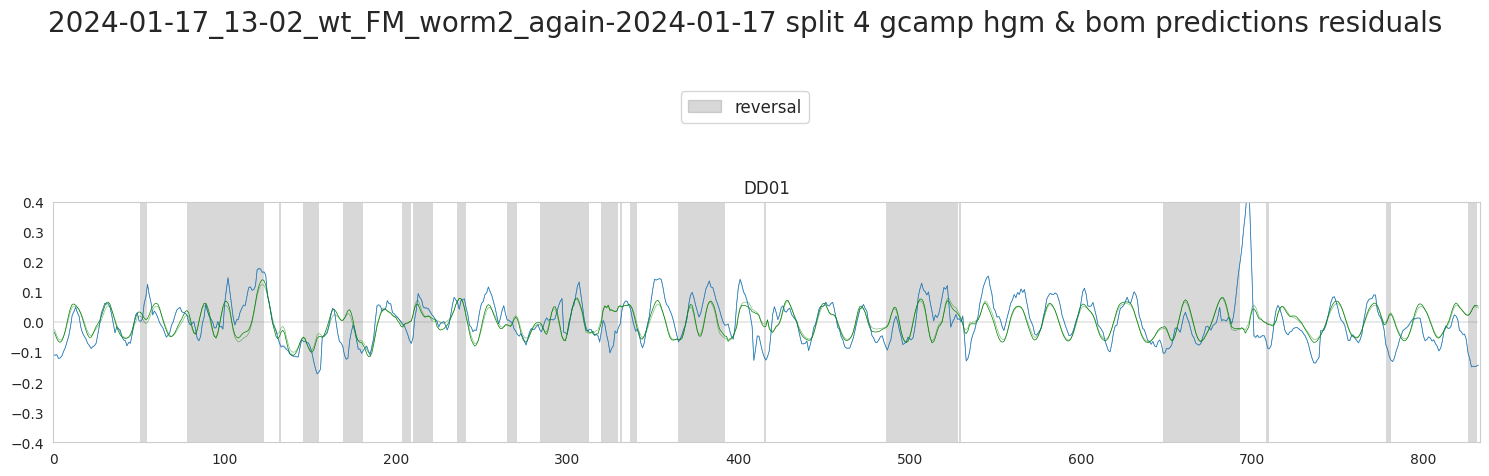

In [58]:
importlib.reload(plot_utils)

plot_id = 14
# all_t = [['AVAR'], ['ALA'], ['VB02'], ['DD01']]
all_t = [['AVAR'], ['ALA'], ['DB01'], ['DD01']]
# all_t = [['DD01']]
t_limits = [(-0.75, 1.5), (-0.2, 0.4), (-0.3, 0.3), (-0.4, 0.4)]
# t_limits = [(-0.4, 0.4)]

for selection_n_traces in all_t:
	current_limit = t_limits[all_t.index(selection_n_traces)]


	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)][:-14]} gcamp hgm & bom definitions manifold',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
		[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n_traces] for i in range(splits)],
		[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n_traces] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=current_limit,
		save_name=f'{plot_id}-{selection_n_traces[0]}-manifolds')


	splits = 5
	plot_utils.plot_traces_x_splits(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)][:-14]} gcamp hgm & bom definitions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
		[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces] for i in range(splits)],
		[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces] for i in range(splits)],
		plot_first=True, plots_per_row=1, ylimits=current_limit,
		save_name=f'{plot_id}-{selection_n_traces[0]}-residuals')


	for i in range(5):
		plot_utils.plot_traces_comparisons(
			f'{filenames_gcamp[file_ids_gcamp.index(plot_id)][:-14]} split {i} gcamp hgm & bom predictions residuals',
			discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
			traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
			[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces],
			 hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n_traces]],
			[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces],
			 bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n_traces]],
			plot_first=False, plots_per_row=1, ylimits=current_limit,
			save_name=f'{plot_id}-{selection_n_traces[0]}-s{i}-predictions')

In [ ]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions manifold',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
	[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n_traces] for i in range(splits)],
	[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][2][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None,
	save_name=f'{plot_id}-{selection_n_traces[0]}-manifolds')

In [ ]:
splits = 5
plot_utils.plot_traces_x_splits(
	f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} gcamp hgm & bom definitions residuals',
	discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
	traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
	[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces] for i in range(splits)],
	[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces] for i in range(splits)],
	plot_first=True, plots_per_row=1, ylimits=None,
	save_name=f'{plot_id}-{selection_n_traces[0]}-residuals')

In [ ]:
for i in range(5):
	plot_utils.plot_traces_comparisons(
		f'{filenames_gcamp[file_ids_gcamp.index(plot_id)]} split {i} gcamp hgm & bom predictions residuals',
		discrete_states_gcamp[file_ids_gcamp.index(plot_id)]['REV'],
		traces_gcamp[file_ids_gcamp.index(plot_id)][selection_n_traces],
		[hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces],
		 hgm_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n_traces]],
		[bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][1][selection_n_traces],
		 bom_pres_res_rec_gcamp[file_ids_gcamp.index(plot_id)][i][0][selection_n_traces]],
		plot_first=False, plots_per_row=1, ylimits=None,
		save_name=f'{plot_id}-{selection_n_traces[0]}-s{i}-predictions')

# GFP

In [ ]:
# if gfp:
# 	plot_utils.plot_traces(f'[{filenames_gfp[file_ids_gfp.index(plot_id_gfp)]}] gfp neural traces residual',
# 						   discrete_states_gfp[file_ids_gfp.index(plot_id_gfp)]['REV'],
# 						   traces_gfp[file_ids_gfp.index(plot_id_gfp)][['VB02', 'AVAR']],
# 						   plots_per_row=1, ylimits=None)

## predict & score

In [ ]:
bom_pres_res_rec_gfp = [[
	predict_wrapper(bom, traces_gfp[i].values, eigenworms_gfp[i].values, params, traces_gfp[i].columns) for params in bom_models_params_gfp[i]
] for i in range(len(traces_gfp))]

hgm_pres_res_rec_gfp = [[
	predict_wrapper(hgm, traces_gfp[i].values, eigenworms_gfp[i].values, params, traces_gfp[i].columns) for params in hgm_models_params_gfp[i]
] for i in range(len(traces_gfp))]

In [ ]:
# splits_gfp = [list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values)) for i in range(len(filenames_gfp))]
#
# bom_models_scores_gfp = [
# 	np.array([
# 		[(r2_score(t, t_p) if t.var() > 0 else 0) for t, t_p in zip(trace.values[eval].T, trace_pred.values[eval].T)]
# 		for (trace_pred, trace, _), (_, eval) in zip(pres_res_rec, splits)])
# 	for pres_res_rec, splits in zip(bom_pres_res_rec_gfp, splits_gfp)
# ]
# hgm_models_scores_gfp = [
# 	np.array([
# 		[(r2_score(t, t_p) if t.var() > 0 else 0) for t, t_p in zip(trace.values[eval].T, trace_pred.values[eval].T)]
# 		for (trace_pred, trace, _), (_, eval) in zip(pres_res_rec, splits)])
# 	for pres_res_rec, splits in zip(hgm_pres_res_rec_gfp, splits_gfp)
# ]



bom_models_scores_gfp = list()
hgm_models_scores_gfp = list()

for i in range(len(filenames_gfp)):
	splits = list(StratifiedKFold(n_splits=5, shuffle=False).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	N = traces_gfp[i].values
	B_ll = eigenworms_gfp[i].values
	B_hl = discrete_states_gfp[i].values

	bom_neuron_scores_per_split = list()
	hgm_neuron_scores_per_split = list()

	for s_id, (train, eval) in enumerate(splits):
		N_train, N_eval = N[train], N[eval]
		B_hl_train, B_hl_eval = B_hl[train], B_hl[eval]
		B_ll_train, B_ll_eval = B_ll[train], B_ll[eval]

		prep_data_train = PrepData(
			N_mean=tuple((map(float, N_train.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_train, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_train.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_train, axis=0)) == 0.0, 1.0, B_hl_std))))
		)
		prep_data_eval = PrepData(
			N_mean=tuple((map(float, N_eval.mean(axis=0)))),
			N_std=tuple((map(float, jnp.where((N_std := jnp.std(N_eval, axis=0)) == 0.0, 1.0, N_std)))),
			B_hl_mean=tuple((map(float, B_hl_eval.mean(axis=0)))),
			B_hl_std=tuple((map(float, jnp.where((B_hl_std := jnp.std(B_hl_eval, axis=0)) == 0.0, 1.0, B_hl_std))))
		)

		bom_params = bom_models_params_gfp[i][s_id]
		bom_score_per_neuron = bom.score_fn(bom_params, N_eval, B_ll_eval, prep_data_eval)
		bom_neuron_scores_per_split.append(bom_score_per_neuron)

		hgm_params = hgm_models_params_gfp[i][s_id]
		hgm_score_per_neuron = hgm.score_fn(hgm_params, N_eval, B_ll_eval, prep_data_eval)
		hgm_neuron_scores_per_split.append(hgm_score_per_neuron)

	bom_models_scores_gfp.append(np.array(bom_neuron_scores_per_split))
	hgm_models_scores_gfp.append(np.array(hgm_neuron_scores_per_split))

## performance

In [ ]:
if gfp:
	neuron_scores_gfp = assemble(filenames_gfp, traces_gfp, bom_models_scores_gfp, hgm_models_scores_gfp)

In [ ]:
if gfp:
	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n}, neuron_scores_gfp,
									 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
									 save_name=f'{plot_id}-performance-selected-gfp')

	plot_utils.plot_performance_plot({key: neuron_scores_gcamp[key] for key in selection_n_perf}, neuron_scores_gfp,
									 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
									 save_name=f'{plot_id}-performance-best-gfp')

	plot_utils.plot_performance_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
									 save_name=f'{plot_id}-performance-all-gfp')

In [ ]:
if gfp:
	plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n}, neuron_scores_gfp,
									 limits=(-0.5, 0.5, -0.5, 0.5), content_size=20,
									 save_name=f'{plot_id}-improvement-selected-gfp')

	plot_utils.plot_improvement_plot({key: neuron_scores_gcamp[key] for key in selection_n_impr}, neuron_scores_gfp,
									 limits=(-1, 0.5, -0.15, 0.25), content_size=20,
									 save_name=f'{plot_id}-improvement-best-gfp')

	plot_utils.plot_improvement_plot(neuron_scores_gcamp, neuron_scores_gfp,
									 limits=(-1, 0.5, -0.15, 0.25), content_size=20,
									 save_name=f'{plot_id}-improvement-all-gfp')